In [1]:
# We start by importing all the necessary packages
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import torch
from tqdm import tqdm
import math
from Python_files import time_integration_functions as TST
from Python_files import TLM_Test as TT
from Python_files import ETLM as ETLMC
from Python_files import LETLM_ensemble as LETLMC
from Python_files import IETLM_ensemble as IETLMC
from Python_files import GETLM as GETLMC
from Python_files import GETLM_experiment_neat as GEN

In [2]:
# we now define stuff as required
model = TST.rk4_L96

N = 40 # The number of grid points
dx = 1 # The spacing
F_L96 = 8 # The Lorenz 96 forcing term
dt = 0.01 # This gives a time step of six hours
timesteps =  14400 # This moves the model forward ten years
alpha = 1 # set for no reason
beta = 1 # set for no reason
model_parameters = (N, dx, dt, alpha, beta, F_L96)

perturbation_size = 10**(-7)
ensemble_size = 25
num_steps = 15
trials = 10
LETLM_stencil = [[0], [-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5]]
IETLM_stencil = [[-2,-1,0,1], [-2,-1,0,1]]
GETLM_stencil = [[-0],[-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5],[]]

x_values = np.arange(1, num_steps+1)  


In [3]:
GETLM_stencils = [[[-0],[-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5],[]],
                  [[-0],[-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5],[]],
                  [[-0],[-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4],[]],
                  [[-0],[-6,-5,-4,-3,-2,-1,0,1,2,3,4],[]],
                  [[-0],[-6,-5,-4,-3,-2,-1,0,1,2,3],[]],
                  [[-0],[-5,-4,-3,-2,-1,0,1,2,3],[]],
                  [[-0],[-5,-4,-3,-2,-1,0,1,2],[]],
                  [[-0],[-4,-3,-2,-1,0,1,2],[]],
                  [[-0],[-4,-3,-2,-1,0,1,],[]],
                  [[-0],[-3,-2,-1,0,1],[]]]




In [4]:
# LETLM_stencils = [[[-0],[-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5]],
#                   [[-0],[-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5]],
#                   [[-0],[-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4]],
#                   [[-0],[-6,-5,-4,-3,-2,-1,0,1,2,3,4]],
#                   [[-0],[-6,-5,-4,-3,-2,-1,0,1,2,3]],
#                   [[-0],[-5,-4,-3,-2,-1,0,1,2,3]],
#                   [[-0],[-5,-4,-3,-2,-1,0,1,2]],
#                   [[-0],[-4,-3,-2,-1,0,1,2]],
#                   [[-0],[-4,-3,-2,-1,0,1,]],
#                   [[-0],[-3,-2,-1,0,1]]]

  0%|          | 0/10 [00:00<?, ?it/s]/Users/imilesfine/PhD_Work/2026/GETLM_L96/Python_files/TLM_Test.py:18: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4483.)
  TLM_test_result = torch.sqrt((alpha.T @ alpha)/(beta.T @ beta))
100%|██████████| 10/10 [00:04<00:00,  2.25it/s]
/Users/imilesfine/PhD_Work/2026/GETLM_L96/Python_files/GETLM_experiment_neat.py:329: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  LETLM_mean = torch.mean(torch.tensor(LETLM_TT_result_large), dim = 0)
/Users/imilesfine/PhD_

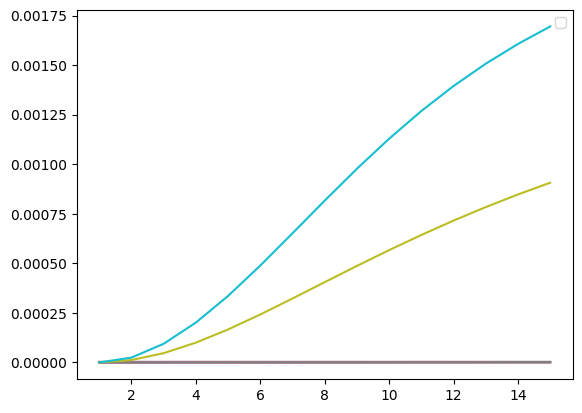

In [ ]:
result_5=[]
result_10=[]
LETLM_10 =[]
LETLM_5 =[]
width = []
for i in range(len(GETLM_stencils)):
    GETLM_stencil = GETLM_stencils[i]
    LETLM_stencil = GETLM_stencils[i]

    width.append(len(GETLM_stencil[1]))
    LETLM_TT_result, IETLM_TT_result, GETLM_1_TT_result, GETLM_2_TT_result, GETLM_3_TT_result, GETLM_4_TT_result = GEN.GETLM_experiment_trials(model, model_parameters, perturbation_size, ensemble_size, num_steps, trials, LETLM_stencil, IETLM_stencil, GETLM_stencil)
    plt.plot(x_values, GETLM_1_TT_result,label = 'width = ')
    result_5.append(GETLM_1_TT_result[4])
    result_10.append(GETLM_1_TT_result[9])
    LETLM_5.append(LETLM_TT_result[4])
    LETLM_10.append(LETLM_TT_result[9])
plt.legend()
plt.show()



In [6]:
GETLM_stencils = [[[-0],[-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5],[0]],
                  [[-0],[-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5],[0]],
                  [[-0],[-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4],[0]],
                  [[-0],[-6,-5,-4,-3,-2,-1,0,1,2,3,4],[0]],
                  [[-0],[-6,-5,-4,-3,-2,-1,0,1,2,3],[0]],
                  [[-0],[-5,-4,-3,-2,-1,0,1,2,3],[0]],
                  [[-0],[-5,-4,-3,-2,-1,0,1,2],[0]],
                  [[-0],[-4,-3,-2,-1,0,1,2],[0]],
                  [[-0],[-4,-3,-2,-1,0,1,],[0]],
                  [[-0],[-3,-2,-1,0,1],[0]]]

100%|██████████| 10/10 [00:03<00:00,  3.08it/s]


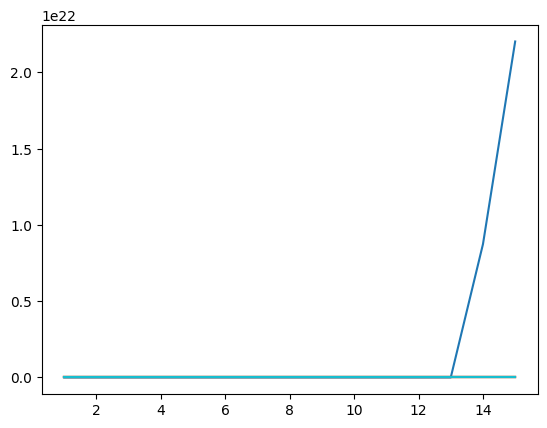

In [7]:
result_5_P=[]
result_10_P=[]
LETLM_10 =[]
LETLM_5 =[]
width = []
for i in range(len(GETLM_stencils)):
    GETLM_stencil = GETLM_stencils[i]
    LETLM_stencil = GETLM_stencils[i]

    width.append(len(GETLM_stencil[1]))
    LETLM_TT_result, IETLM_TT_result, GETLM_1_TT_result, GETLM_2_TT_result, GETLM_3_TT_result, GETLM_4_TT_result = GEN.GETLM_experiment_trials(model, model_parameters, perturbation_size, ensemble_size, num_steps, trials, LETLM_stencil, IETLM_stencil, GETLM_stencil)
    plt.plot(x_values, GETLM_1_TT_result)
    result_5_P.append(GETLM_1_TT_result[4])
    result_10_P.append(GETLM_1_TT_result[9])
    LETLM_5.append(LETLM_TT_result[4])
    LETLM_10.append(LETLM_TT_result[9])

plt.show()



In [8]:
GETLM_stencils = [[[-2,-1,0,1],[-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5],[0]],
                  [[-2,-1,0,1],[-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5],[0]],
                  [[-2,-1,0,1],[-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4],[0]],
                  [[-2,-1,0,1],[-6,-5,-4,-3,-2,-1,0,1,2,3,4],[0]],
                  [[-2,-1,0,1],[-6,-5,-4,-3,-2,-1,0,1,2,3],[0]],
                  [[-2,-1,0,1],[-5,-4,-3,-2,-1,0,1,2,3],[0]],
                  [[-2,-1,0,1],[-5,-4,-3,-2,-1,0,1,2],[0]],
                  [[-2,-1,0,1],[-4,-3,-2,-1,0,1,2],[0]],
                  [[-2,-1,0,1],[-4,-3,-2,-1,0,1,],[0]],
                  [[-2,-1,0,1],[-3,-2,-1,0,1],[0]]]

GETLM_stencils = [[[-2,-1,0,1],[-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5],[]],
                  [[-2,-1,0,1],[-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5],[]],
                  [[-2,-1,0,1],[-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4],[]],
                  [[-2,-1,0,1],[-6,-5,-4,-3,-2,-1,0,1,2,3,4],[]],
                  [[-2,-1,0,1],[-6,-5,-4,-3,-2,-1,0,1,2,3],[]],
                  [[-2,-1,0,1],[-5,-4,-3,-2,-1,0,1,2,3],[]],
                  [[-2,-1,0,1],[-5,-4,-3,-2,-1,0,1,2],[]],
                  [[-2,-1,0,1],[-4,-3,-2,-1,0,1,2],[]],
                  [[-2,-1,0,1],[-4,-3,-2,-1,0,1,],[]],
                  [[-2,-1,0,1],[-3,-2,-1,0,1],[]]]

100%|██████████| 10/10 [00:03<00:00,  2.60it/s]


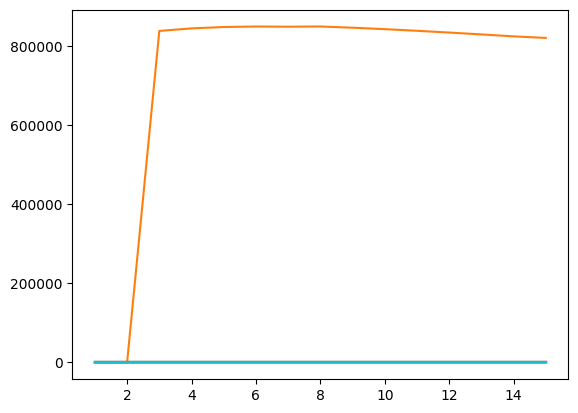

In [9]:
result_5_F=[]
result_10_F=[]
LETLM_10 =[]
LETLM_5 =[]
width = []
for i in range(len(GETLM_stencils)):
    GETLM_stencil = GETLM_stencils[i]
    LETLM_stencil = GETLM_stencils[i]

    width.append(len(GETLM_stencil[1]))
    LETLM_TT_result, IETLM_TT_result, GETLM_1_TT_result, GETLM_2_TT_result, GETLM_3_TT_result, GETLM_4_TT_result = GEN.GETLM_experiment_trials(model, model_parameters, perturbation_size, ensemble_size, num_steps, trials, LETLM_stencil, IETLM_stencil, GETLM_stencil)
    plt.plot(x_values, GETLM_1_TT_result)
    result_5_F.append(GETLM_1_TT_result[4])
    result_10_F.append(GETLM_1_TT_result[9])
    LETLM_5.append(LETLM_TT_result[4])
    LETLM_10.append(LETLM_TT_result[9])

plt.show()


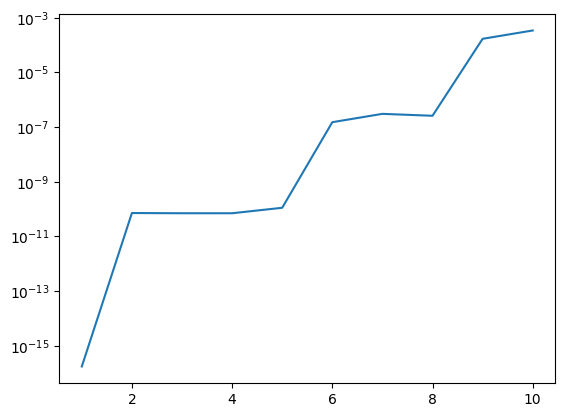

In [10]:
x_values_2 = np.arange(1, len(result_5)+1)
plt.plot(x_values_2, result_5)
plt.yscale('log')

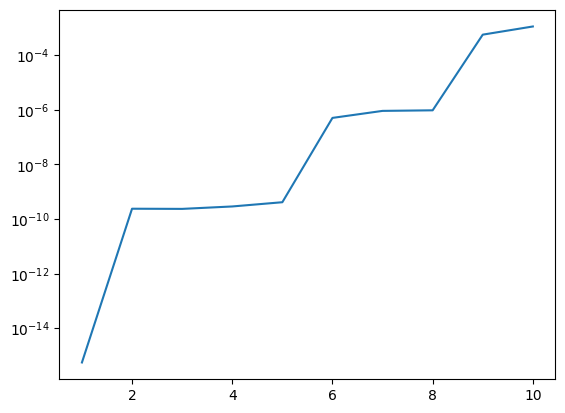

In [11]:
x_values_2 = np.arange(1, len(result_5)+1)
plt.plot(x_values_2, result_10)
plt.yscale('log')

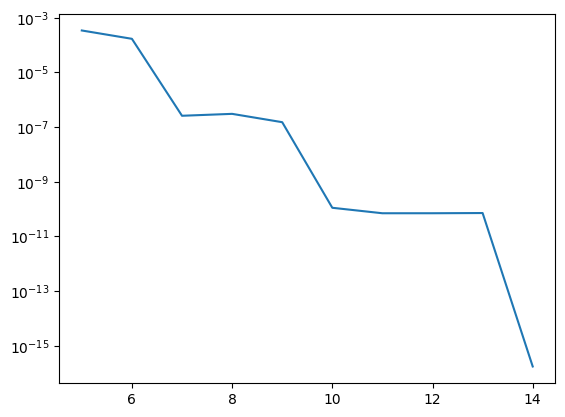

In [12]:
x_values_2 = np.arange(1, len(result_5)+1)
plt.plot(width, result_5)
plt.yscale('log')

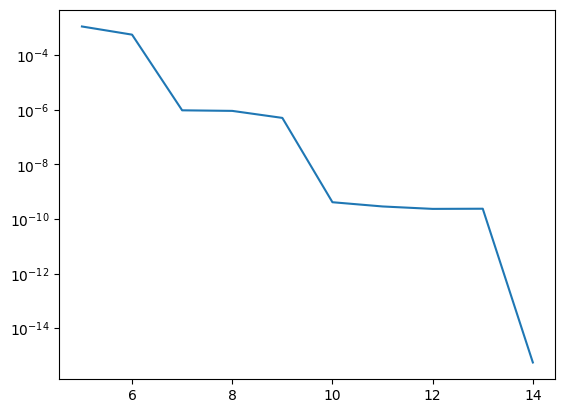

In [13]:
x_values_2 = np.arange(1, len(result_5)+1)
plt.plot(width, result_10)
plt.yscale('log')

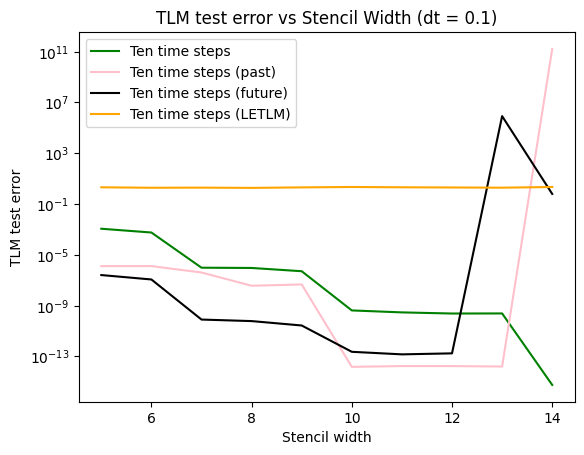

In [14]:
x_values_2 = np.arange(1, len(result_5)+1)
# plt.plot(width, result_5, color = 'red', label = 'Five time step')
plt.plot(width, result_10, color = 'green', label = 'Ten time steps')
# plt.plot(width, result_5_P, color = 'purple', label = 'Five time step (past)')
plt.plot(width, result_10_P, color = 'pink', label = 'Ten time steps (past)')
# plt.plot(width, result_5_F, color = 'violet', label = 'Five time step (future)')
plt.plot(width, result_10_F, color = 'black', label = 'Ten time steps (future)')
plt.plot(width, LETLM_10, color = 'orange', label = 'Ten time steps (LETLM)')
# plt.plot(width, LETLM_5, color = 'yellow', label = 'Five time steps (LETLM)')

plt.ylabel('TLM test error')
plt.xlabel('Stencil width')
plt.yscale('log')
plt.legend()
plt.title('TLM test error vs Stencil Width (dt = 0.1)')
plt.show()

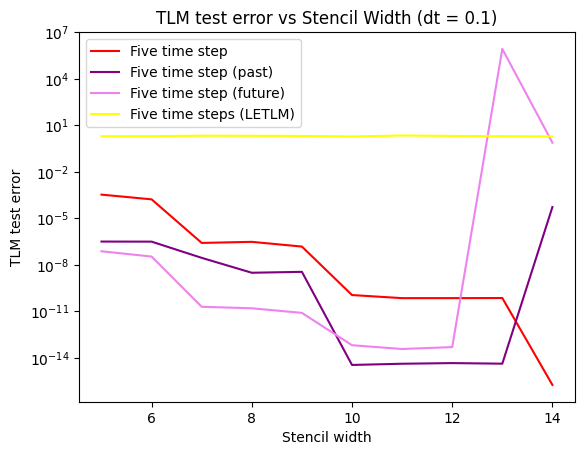

In [15]:
x_values_2 = np.arange(1, len(result_5)+1)
plt.plot(width, result_5, color = 'red', label = 'Five time step')
# plt.plot(width, result_10, color = 'green', label = 'Ten time steps')
plt.plot(width, result_5_P, color = 'purple', label = 'Five time step (past)')
# plt.plot(width, result_10_P, color = 'pink', label = 'Ten time steps (past)')
plt.plot(width, result_5_F, color = 'violet', label = 'Five time step (future)')
# plt.plot(width, result_10_F, color = 'black', label = 'Ten time steps (future)')
# plt.plot(width, LETLM_10, color = 'orange', label = 'Ten time steps (LETLM)')
plt.plot(width, LETLM_5, color = 'yellow', label = 'Five time steps (LETLM)')

plt.ylabel('TLM test error')
plt.xlabel('Stencil width')
plt.yscale('log')
plt.legend()
plt.title('TLM test error vs Stencil Width (dt = 0.1)')
plt.show()

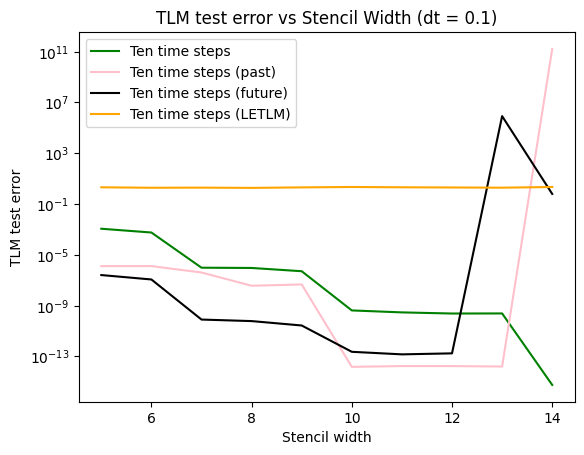

In [16]:
x_values_2 = np.arange(1, len(result_5)+1)
# plt.plot(width, result_5, color = 'red', label = 'Five time step')
plt.plot(width, result_10, color = 'green', label = 'Ten time steps')
# plt.plot(width, result_5_P, color = 'purple', label = 'Five time step (past)')
plt.plot(width, result_10_P, color = 'pink', label = 'Ten time steps (past)')
# plt.plot(width, result_5_F, color = 'violet', label = 'Five time step (future)')
plt.plot(width, result_10_F, color = 'black', label = 'Ten time steps (future)')
plt.plot(width, LETLM_10, color = 'orange', label = 'Ten time steps (LETLM)')
# plt.plot(width, LETLM_5, color = 'yellow', label = 'Five time steps (LETLM)')

plt.ylabel('TLM test error')
plt.xlabel('Stencil width')
plt.yscale('log')
plt.legend()
plt.title('TLM test error vs Stencil Width (dt = 0.1)')
plt.show()